Text(0.5, 1.0, 'Trajectories of Particle 2 in xy-plane')

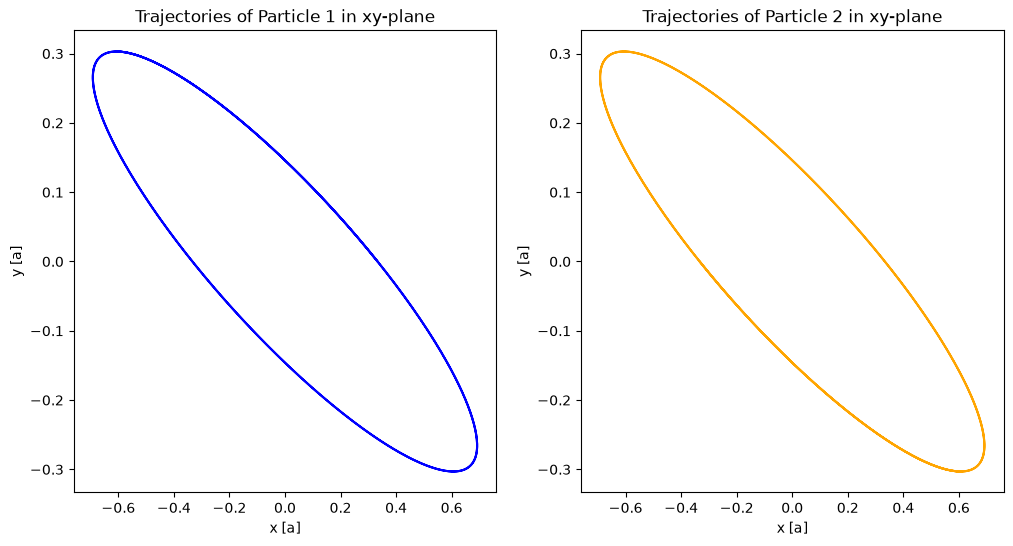

In [14]:
"""
Tasks (a):  harmonic dumb bell sympletic ingegration:

1. Plot the trajectories of the position of the two particles in xy-plane;
2. Plot the deviations of total momentum, total angular momentum and total energy 
   from their initial values as a function of time;
3. Determine the maximal relative energy deviation.
"""

import numpy as np
import matplotlib.pyplot as plt
import matplotlib as mpl

r1_0 = np.array([1/3, 0, 0])        # Initial position of particle 1 in a
r2_0 = np.array([-1/3, 0, 0])       # Initial position of particle 2 in a
p1_0 = np.array([-6/7, 3/7, -2/7])  # Initial momentum of particle 1
p2_0 = np.array([6/7, -3/7, 2/7])   # Initial momentum of particle 2
T = 10                              # Total simulation time in omega^-1 units
dt = 1e-2                           # Time step in omega^-1 units
k = 1                               # Spring constant for harmonic oscillator
a = 1                               # Length scale in a units
m1 = 1                              # Mass of particle 1
m2 = 1                              # Mass of particle 2

def F(r1, r2):
    # force function for harmonic oscillator
    return -k * (r1 - r2)


"""
1. Plot the trajectories of the position of the two particles in xy-plane;
"""

def verlet(r1_0, r2_0, p1_0, p2_0, T, dt, k, m1, m2, F):
    # Molecular dynamics simulation using Velocity-Verlet algorithm

    # r1_0, r2_0 (array): initial positions of particles 1 and 2
    # p1_0, p2_0 (array): initial momenta of particles 1 and 2
    # T (float): total simulation time
    # dt (float): time step
    # m1, m2 (float): masses of particles 1 and 2

    r1 = np.empty((int(T/dt)+1, 3))
    r2 = np.empty((int(T/dt)+1, 3))
    p1 = np.empty((int(T/dt)+1, 3))
    p2 = np.empty((int(T/dt)+1, 3))
    r1[0] = r1_0
    r2[0] = r2_0
    p1[0] = p1_0
    p2[0] = p2_0
    # Create arrays to store positions and momenta at each time step
    dt_ = np.linspace(0, T, int(T/dt))  # Create time array


    for i in range(int(T/dt)):
        # for each time step

        p1_half = p1[i] + 0.5 * dt * F(r1[i], r2[i])  # Update momentum of particle 1 at half step
        p2_half = p2[i] + 0.5 * dt * F(r2[i], r1[i])  # Same for particle 2
        
        r1[i+1] = r1[i] + dt * p1_half / m1      # Update position of particle 1
        r2[i+1] = r2[i] + dt * p2_half / m2
        
        p1[i+1] = p1_half + 0.5 * dt * F(r1[i+1], r2[i+1])  # Update momentum of particle 1 at full step
        p2[i+1] = p2_half + 0.5 * dt * F(r2[i+1], r1[i+1])

    return r1, r2, p1, p2  # Return arrays of positions and momenta


r1, r2, p1, p2 = verlet(r1_0, r2_0, p1_0, p2_0, T, dt, k, m1, m2, F)
# Run simulation with unit masses

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 6))

ax1.plot(r1[:, 0], r1[:, 1], label='Particle 1', color='blue')
ax1.set_xlabel('x [a]')
ax1.set_ylabel('y [a]')
ax1.set_title('Trajectories of Particle 1 in xy-plane')

ax2.plot(r2[:, 0], r2[:, 1], label='Particle 2', color='orange')
ax2.set_xlabel('x [a]')
ax2.set_ylabel('y [a]')
ax2.set_title('Trajectories of Particle 2 in xy-plane')

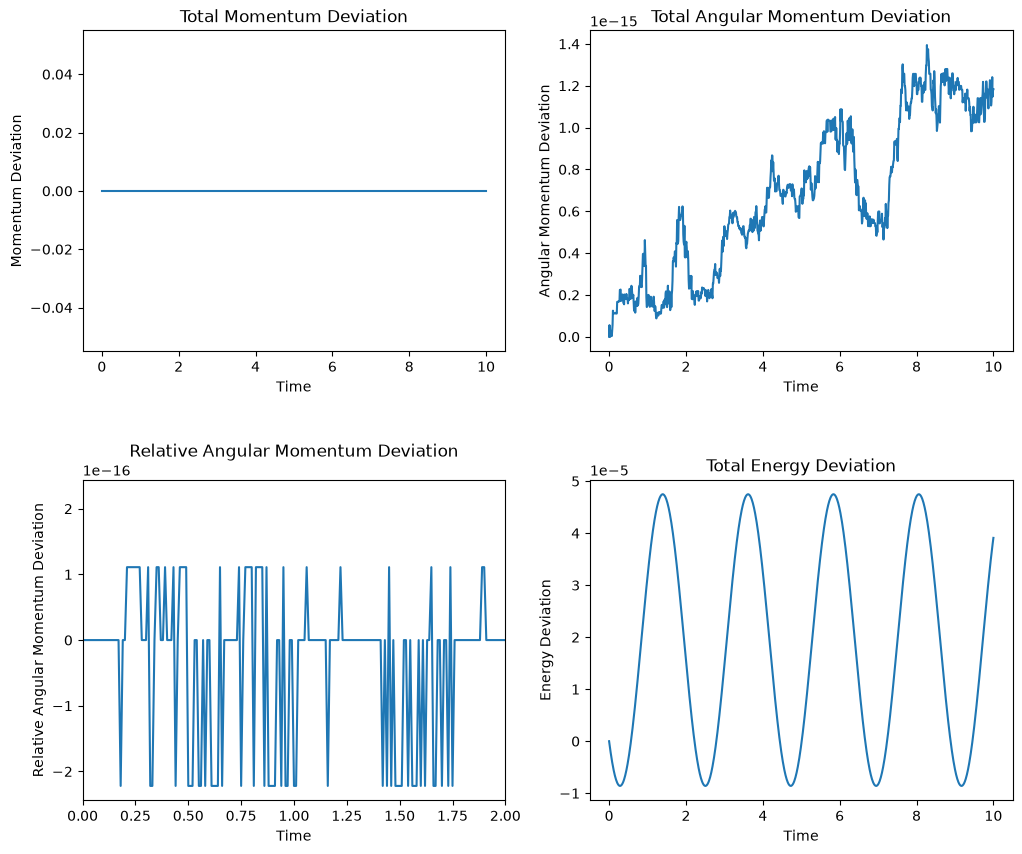

In [15]:
"""
2. Plot the deviations of total momentum, total angular momentum and total energy
"""

t = np.linspace(0, T, 1001)  # time array from 0 to 10 seconds

P_total = p1 + p2  # Total momentum
P_initial = p1_0 + p2_0  # Initial total momentum
P_dev = np.linalg.norm(P_total - P_initial, axis = 1)  # Total momentum deviation

J_total = np.cross(r1, p1) + np.cross(r2, p2)
J_initial = np.cross(r1_0, p1_0) + np.cross(r2_0, p2_0)  # Initial total angular momentum
J_dev = np.linalg.norm(J_total - J_initial, axis = 1)  # Total angular momentum deviation
J_ = 1 - (np.sum(J_total * J_initial, axis = 1) / (np.linalg.norm(J_initial) * np.linalg.norm(J_total, axis = 1)))  # Relative angular momentum deviation

E_kinetic = 0.5 * ((np.sum(p1**2, axis = 1) / m1 + np.sum(p2**2, axis = 1) / m2))  # Total kinetic energy
E_potential = 0.5 * k * np.sum((r1-r2)**2, axis = 1)  # Total potential energy
E_initial = 0.5 * ((np.sum(p1_0**2) / m1 + np.sum(p2_0**2) / m2)) + 0.5 * k * np.sum((r1_0-r2_0)**2)  # Initial total energy
E_total = E_kinetic + E_potential
E_dev = E_total - E_initial  # Total energy deviation

fig, ((ax1, ax2), (ax3, ax4)) = plt.subplots(2, 2, figsize=(12, 10))

ax1.plot(t, P_dev)
ax1.set_xlabel('Time')
ax1.set_ylabel('Momentum Deviation')
ax1.set_title('Total Momentum Deviation')

ax2.plot(t, J_dev)
ax2.set_xlabel('Time')
ax2.set_ylabel('Angular Momentum Deviation')
ax2.set_title('Total Angular Momentum Deviation')

ax3.plot(t, J_)
ax3.set_xlabel('Time')
ax3.set_ylabel('Relative Angular Momentum Deviation')
ax3.set_title('Relative Angular Momentum Deviation')
ax3.set_xlim(0, 2)

ax4.plot(t, E_dev)
ax4.set_xlabel('Time')
ax4.set_ylabel('Energy Deviation')
ax4.set_title('Total Energy Deviation')

fig.subplots_adjust(hspace=0.4)

In [16]:
"""
3. Determine the maximal relative energy deviation for dt = 1e-2 and dt = 4 * 1e-2.
"""

E_rel = E_dev / E_initial  # Relative energy deviation
print("Maximal relative energy deviation:", np.max(np.abs(E_rel)))

Maximal relative energy deviation: 3.885302544311258e-05


Maximal relative energy deviation: 0.0006712717768938522


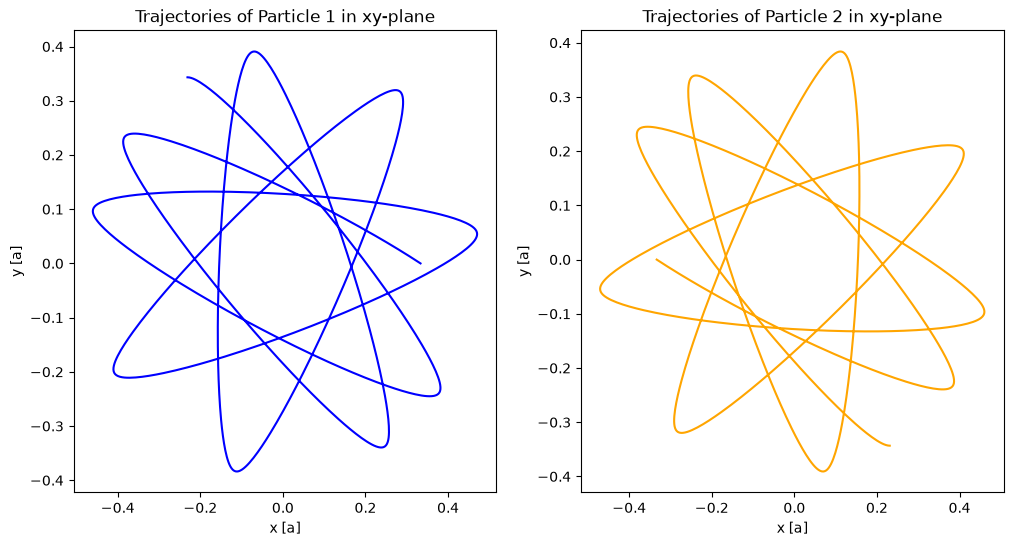

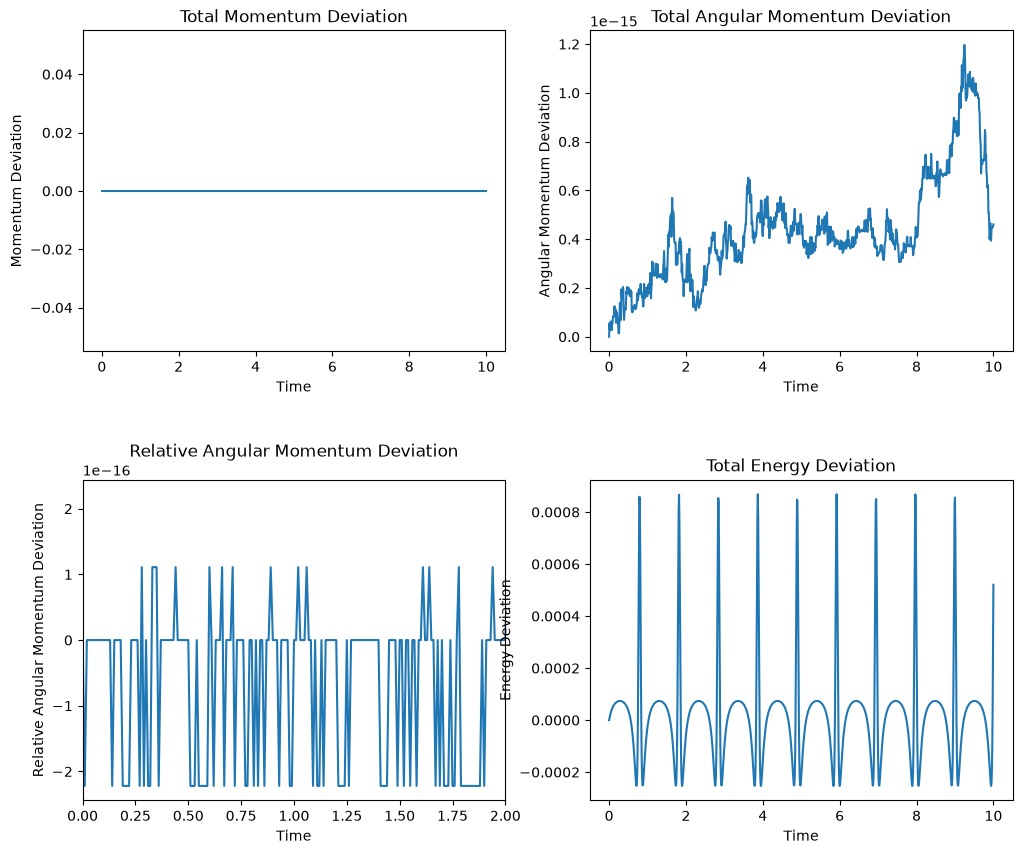

In [17]:
"""
Task (b): anharmonic dumb bell sympletic integration

1. Repeat above steps for FENE potential;
2. Compare the results with those of the harmonic potential.
"""

def F_FENE(r1, r2):
    # Force function for FENE potential

    return -(r1 - r2) / (a**2 - np.sum((r1 - r2)**2))    # FENE force formula

r1_F, r2_F, p1_F, p2_F = verlet(r1_0, r2_0, p1_0, p2_0, T, dt, k, m1, m2, F_FENE)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 6))

ax1.plot(r1_F[:, 0], r1_F[:, 1], label='Particle 1', color='blue')
ax1.set_xlabel('x [a]')
ax1.set_ylabel('y [a]')
ax1.set_title('Trajectories of Particle 1 in xy-plane')

ax2.plot(r2_F[:, 0], r2_F[:, 1], label='Particle 2', color='orange')
ax2.set_xlabel('x [a]')
ax2.set_ylabel('y [a]')
ax2.set_title('Trajectories of Particle 2 in xy-plane')



P_total = p1_F + p2_F  # Total momentum
P_initial = p1_0 + p2_0  # Initial total momentum
P_dev = np.linalg.norm(P_total - P_initial, axis = 1)  # Total momentum deviation

J_total = np.cross(r1_F, p1_F) + np.cross(r2_F, p2_F)
J_initial = np.cross(r1_0, p1_0) + np.cross(r2_0, p2_0)  # Initial total angular momentum
J_dev = np.linalg.norm(J_total - J_initial, axis = 1)  # Total angular momentum deviation
J_ = 1 - (np.sum(J_total * J_initial, axis = 1) / (np.linalg.norm(J_initial) * np.linalg.norm(J_total, axis = 1)))  # Relative angular momentum deviation



E_kinetic = 0.5 * ((np.sum(p1_F**2, axis = 1) / m1 + np.sum(p2_F**2, axis = 1) / m2))  # Total kinetic energy
E_potential_FENE = -0.5 * np.log(1 - (np.sum((r1_F - r2_F)**2, axis = 1) / a**2))  # Total potential energy for FENE
E_initial = 0.5 * ((np.sum(p1_0**2) / m1 + np.sum(p2_0**2) / m2)) - 0.5 * np.log(1 - (np.sum((r1_0 - r2_0)**2) / a**2))  # Initial total energy
E_total = E_kinetic + E_potential_FENE
E_dev = E_total - E_initial  # Total energy deviation

fig, ((ax1, ax2), (ax3, ax4)) = plt.subplots(2, 2, figsize=(12, 10))

ax1.plot(t, P_dev)
ax1.set_xlabel('Time')
ax1.set_ylabel('Momentum Deviation')
ax1.set_title('Total Momentum Deviation')

ax2.plot(t, J_dev)
ax2.set_xlabel('Time')
ax2.set_ylabel('Angular Momentum Deviation')
ax2.set_title('Total Angular Momentum Deviation')

ax3.plot(t, J_)
ax3.set_xlabel('Time')
ax3.set_ylabel('Relative Angular Momentum Deviation')
ax3.set_title('Relative Angular Momentum Deviation')
ax3.set_xlim(0, 2)

ax4.plot(t, E_dev)
ax4.set_xlabel('Time')
ax4.set_ylabel('Energy Deviation')
ax4.set_title('Total Energy Deviation')

fig.subplots_adjust(hspace=0.4)

E_rel = E_dev / E_initial  # Relative energy deviation
print("Maximal relative energy deviation:", np.max(np.abs(E_rel)))